# Bhili vocabulary extension + LoRA fine-tuning

A compact, reproducible Hindi → Bhili experiment adapted from the team's 42-cell vocabulary-extension workflow.

**Important language caveat:** `mar_Deva` is used as the same unverified target-language proxy as the existing Bhili baseline. It is not evidence that IndicTrans2 officially supports Bhili. The vocabulary extension is custom and does not mutate the pretrained tokenizer.

## Section 1. Environment

Install the pinned tokenizer/model toolkit versions once, restart the Kaggle session, then run verification. Do not start training until the decoder integrity checks pass.

In [1]:
# Section 1.1: install pinned dependencies (run ONCE, then restart the session)
%pip install -q --no-cache-dir \
    "transformers==4.46.3" \
    "tokenizers==0.20.3" \
    "IndicTransToolkit==1.1.1" \
    peft accelerate sacrebleu sentencepiece kagglehub

# Kaggle ships an old torchao that newer peft versions reject. This notebook does not use torchao.
%pip uninstall -y torchao

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
litellm 1.93.2 requires tokenizers<1.0,>=0.21.0, but you have tokenizers 0.20.3 which is incompatible.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
Note: you may need to restart the kernel to use updated packages.
Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Section 1.2: verify packages and GPU (run after the restart)
import sys
import importlib.metadata as metadata
import torch

print("=== Package versions ===")
for package in ["transformers", "tokenizers", "IndicTransToolkit", "torch", "peft", "accelerate", "sacrebleu", "sentencepiece", "torchao"]:
    try:
        print(f"{package:20s}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package:20s}: NOT INSTALLED")

print("\nPython:", sys.version.split()[0])
assert torch.cuda.is_available(), "No GPU. Set Accelerator to GPU T4 and restart the session."
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory (GiB): %.1f" % (torch.cuda.get_device_properties(0).total_memory / 1024**3))

import transformers
assert transformers.__version__ == "4.46.3", "transformers is not 4.46.3: rerun the install cell and restart the session."

=== Package versions ===
transformers        : 4.46.3
tokenizers          : 0.20.3
IndicTransToolkit   : 1.1.1
torch               : 2.11.0+cu128
peft                : 0.20.0
accelerate          : 1.14.0
sacrebleu           : 2.6.0
sentencepiece       : 0.2.2
torchao             : NOT INSTALLED

Python: 3.13.15
GPU: Tesla T4
GPU memory (GiB): 14.6


## Section 2. Authentication and run configuration

**Edit this section only when intentionally creating a different run.** This copy is configured for `MIN_FREQ = 20`, mean initialization, and seed 42. The number of genuinely new target entries is calculated from the attached Bhili training split when candidate selection runs. This notebook starts its own clean run; it does not overwrite the older `bhili_vocab_extended_lora` experiment.

In [3]:
# Section 2.1: imports, Hugging Face login, and Bhili run configuration
import gc, glob, json, math, os, random, re, shutil, time, unicodedata, warnings, zipfile
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import LambdaLR
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

warnings.filterwarnings("ignore")

hf_token = UserSecretsClient().get_secret("HF_TOKEN")
assert hf_token, "Add your Hugging Face access token to Kaggle Secrets as HF_TOKEN."
login(token=hf_token)
print("Hugging Face authentication complete.")

# ---------------- EDIT THESE ----------------
MIN_FREQ = 20       # minimum number of occurrences in the Bhili TRAINING split
INIT = "mean"      # "mean" or "random"
SEED = 42
# --------------------------------------------

DEVICE = torch.device("cuda")
MODEL_ID = "ai4bharat/indictrans2-indic-indic-1B"
SRC_LANG, TGT_LANG = "hin_Deva", "mar_Deva"  # target tag is an unverified Bhili proxy
SRC_COL, TGT_COL = "Hindi", "Bhili"

# Training configuration: aligned with the saved Bhili baseline where applicable.
BATCH_SIZE, GRAD_ACCUM = 4, 4
NUM_EPOCHS = 10
LEARNING_RATE, WEIGHT_DECAY = 1e-4, 0.01
WARMUP_RATIO, MAX_GRAD_NORM = 0.03, 1.0
PATIENCE, MIN_DELTA = 2, 0.001
MAX_LEN = 256
MAX_EPOCHS_THIS_SESSION = NUM_EPOCHS  # lower to stop after N completed epochs, then resume later
EXPECTED_NEW_TOKENS = {50: 166}

RUN_NAME = f"bhili_ext_f{MIN_FREQ}_{INIT}_s{SEED}"
RUN_DIR = Path("/kaggle/working") / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
PRED_DIR = RUN_DIR / "predictions"
PRED_DIR.mkdir(parents=True, exist_ok=True)

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

seed_everything(SEED)
assert INIT in ("mean", "random")
print("Run:", RUN_NAME, "| output folder:", RUN_DIR)
print("Direction:", SRC_COL, "→", TGT_COL, "| target-tag caveat:", TGT_LANG)
with open(RUN_DIR / "experiment_config.json", "w", encoding="utf-8") as f:
    json.dump({"run_name": RUN_NAME, "model_id": MODEL_ID, "src_lang": SRC_LANG, "tgt_lang_proxy": TGT_LANG,
               "source_column": SRC_COL, "target_column": TGT_COL, "min_frequency": MIN_FREQ,
               "initialization": INIT, "seed": SEED, "batch_size": BATCH_SIZE,
               "gradient_accumulation": GRAD_ACCUM, "epochs": NUM_EPOCHS, "learning_rate": LEARNING_RATE,
               "weight_decay": WEIGHT_DECAY, "max_length": MAX_LEN}, f, indent=2, ensure_ascii=False)

Hugging Face authentication complete.
Run: bhili_ext_f20_mean_s42 | output folder: /kaggle/working/bhili_ext_f20_mean_s42
Direction: Hindi → Bhili | target-tag caveat: mar_Deva


## Section 3. Data

Load the published Bhili Parquet splits used by the existing baseline. Candidate vocabulary selection uses **training text only**; validation selects checkpoints; test is held out for final evaluation.

In [4]:
# Section 3.1: locate and load the exact Bhili splits
INPUT_ROOT = Path("/kaggle/input")
print("Top-level input folders:")
for p in sorted(INPUT_ROOT.iterdir()):
    print(" -", p.name)

matches = [p for p in INPUT_ROOT.rglob("bhili_train.parquet") if p.parent.name == "splits"]
assert len(matches) == 1, (
    f"Expected one splits/bhili_train.parquet, found {len(matches)}. "
    "Attach the Common Tribal Languages Preprocessing dataset."
)
SPLIT_DIR = matches[0].parent
train_df = pd.read_parquet(SPLIT_DIR / "bhili_train.parquet").reset_index(drop=True)
val_df = pd.read_parquet(SPLIT_DIR / "bhili_validation.parquet").reset_index(drop=True)
test_df = pd.read_parquet(SPLIT_DIR / "bhili_test.parquet").reset_index(drop=True)

for name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    assert {SRC_COL, TGT_COL} <= set(df.columns), f"{name}: missing {SRC_COL}/{TGT_COL}; found {df.columns.tolist()}"
    assert df[[SRC_COL, TGT_COL]].notna().all().all(), f"{name}: missing values"
    assert (df[SRC_COL].astype(str).str.strip() != "").all(), f"{name}: empty Hindi sentences"
    assert (df[TGT_COL].astype(str).str.strip() != "").all(), f"{name}: empty Bhili sentences"
    print(f"{name:11s}: {len(df):,} rows")

assert (len(train_df), len(val_df), len(test_df)) == (17817, 990, 990), "Split sizes differ from the existing Bhili experiment."
pair_sets = {name: set(df[[SRC_COL, TGT_COL]].itertuples(index=False, name=None))
             for name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]}
for a,b in [("train","validation"),("train","test"),("validation","test")]:
    overlap = len(pair_sets[a] & pair_sets[b])
    print(f"Exact pair overlap {a}/{b}: {overlap}")
    assert overlap == 0, f"Exact pair overlap found between {a} and {b}."
print("Example Hindi:", train_df.iloc[0][SRC_COL])
print("Example Bhili:", train_df.iloc[0][TGT_COL])

Top-level input folders:
 - datasets
train      : 17,817 rows
validation : 990 rows
test       : 990 rows
Exact pair overlap train/validation: 0
Exact pair overlap train/test: 0
Exact pair overlap validation/test: 0
Example Hindi: इंफ्रास्ट्रक्चर और टेक्नोलॉजी निवेश में वृद्धि हो रही है।
Example Bhili: इन्‍फ्रास्‍ट्रक्‍चर मानकों नी रीतें एआई अनुसंधान अनें विकास करवा नों प्रोत्‍साहन मळिरों से।


## Section 4. Tokenizer and source preprocessor

Keep the pretrained IndicTrans2 tokenizer unchanged. The extension is implemented as a custom mapping for Bhili target words, plus trainable rows in the decoder embedding and output projection. `mar_Deva` is a proxy tag inherited from the existing baseline; Bhili support is unverified.

In [5]:
# Section 4.1: tokenizer and IndicProcessor
from transformers import AutoTokenizer
from IndicTransToolkit import IndicProcessor

tok = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True, token=hf_token)
processor = IndicProcessor(inference=True)
sp = tok.tgt_spm
BASE_TARGET_VOCAB_SIZE = len(tok.tgt_encoder)
EOS_ID, PAD_ID, DEC_START_ID, UNK_ID = 2, 1, 2, 3

print("Tokenizer:", type(tok).__name__, "| source vocab:", tok.src_vocab_size, "| target vocab:", tok.tgt_vocab_size)
assert (tok.src_vocab_size, tok.tgt_vocab_size) == (122706, 122672)
assert BASE_TARGET_VOCAB_SIZE == 122672
assert (tok.eos_token_id, tok.pad_token_id) == (EOS_ID, PAD_ID)
print("Tokenizer remains unchanged; target language tag remains an unverified proxy.")

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenization_indictrans.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/ai4bharat/indictrans2-indic-indic-1B:
- tokenization_indictrans.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


dict.SRC.json: 0.00B [00:00, ?B/s]

dict.TGT.json: 0.00B [00:00, ?B/s]

model.SRC:   0%|          | 0.00/3.26M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/96.0 [00:00<?, ?B/s]

Tokenizer: IndicTransTokenizer | source vocab: 122706 | target vocab: 122672
Tokenizer remains unchanged; target language tag remains an unverified proxy.


## Section 5. Candidate words for this run

Select whitespace-delimited forms found in the Bhili **training split** that occur at least `MIN_FREQ` times, are not punctuation/symbol-only, and require multiple original target-token pieces. Remove candidates already present as a single original target-vocabulary entry. No validation or test text is used to build the vocabulary.

In [6]:
# Section 5.1: build candidates from training text only and assign extension IDs
train_texts_full = train_df[TGT_COL].astype(str).str.strip().tolist()
word_counts = Counter()
for text in train_texts_full:
    word_counts.update(text.split())
print("Unique whitespace-delimited Bhili forms in training:", len(word_counts))

def _only_punct_or_symbol(word):
    return bool(word) and all(unicodedata.category(ch)[0] in {"P", "S"} for ch in word)

def _contains_no_punctuation_or_symbols(word):
    return bool(word) and all(unicodedata.category(ch)[0] not in {"P", "S"} for ch in word)

rows = []
for word, freq in word_counts.items():
    if freq < 5 or _only_punct_or_symbol(word):
        continue
    pieces = sp.encode(word, out_type=str)
    if len(pieces) > 1:
        rows.append({"word": word, "frequency": int(freq), "piece_count": len(pieces),
                     "existing_pieces": " | ".join(pieces),
                     "potential_piece_reduction": len(pieces) - 1})
clean_candidates = pd.DataFrame(rows)
if not clean_candidates.empty:
    clean_candidates = clean_candidates[
        clean_candidates["word"].map(_contains_no_punctuation_or_symbols)
    ].copy()

existing_target_words = set(tok.tgt_encoder.keys())
def select_candidates(min_freq):
    sub = clean_candidates[
        (clean_candidates["frequency"] >= min_freq) & (clean_candidates["piece_count"] > 1)
    ].drop_duplicates(subset=["word"])
    sub = sub.sort_values(
        ["frequency", "potential_piece_reduction", "word"],
        ascending=[False, False, True], kind="stable"
    ).reset_index(drop=True)
    return sub[~sub["word"].isin(existing_target_words)].reset_index(drop=True)

# Useful threshold audit, computed on this Bhili corpus; these are candidate counts, not separately trained configurations.
audits = []
for freq in [100, 50, 20, 10, 5]:
    chosen = select_candidates(freq)
    audits.append({"minimum_frequency": freq, "new_tokens": len(chosen),
                   "training_occurrences": int(chosen["frequency"].sum()) if len(chosen) else 0,
                   "estimated_piece_reduction": int((chosen["frequency"] * chosen["potential_piece_reduction"]).sum()) if len(chosen) else 0})
display(pd.DataFrame(audits))

new_df = select_candidates(MIN_FREQ)
new_words = new_df["word"].tolist()
if MIN_FREQ in EXPECTED_NEW_TOKENS:
    assert len(new_words) == EXPECTED_NEW_TOKENS[MIN_FREQ], (
        f"Expected {EXPECTED_NEW_TOKENS[MIN_FREQ]} new tokens at frequency {MIN_FREQ}; found {len(new_words)}. "
        "Check that the attached Bhili split dataset matches the established experiment."
    )
assert new_words, "No extension candidates selected."
N_NEW = len(new_words)
EXTENDED_VOCAB_SIZE = BASE_TARGET_VOCAB_SIZE + N_NEW
candidate_to_id = {word: BASE_TARGET_VOCAB_SIZE + i for i, word in enumerate(new_words)}
id_to_candidate = {token_id: word for word, token_id in candidate_to_id.items()}
assert len(set(candidate_to_id.values())) == N_NEW
assert all(word not in existing_target_words for word in candidate_to_id)

print(f"\nMinimum frequency: {MIN_FREQ}")
print(f"Added tokens: {N_NEW}; IDs {BASE_TARGET_VOCAB_SIZE}–{EXTENDED_VOCAB_SIZE - 1}")
print("Selected token occurrences:", int(new_df["frequency"].sum()))
print("First 10 new words:", new_words[:10])
new_df.to_csv(RUN_DIR / "selected_vocabulary.csv", index=False, encoding="utf-8-sig")
with open(RUN_DIR / "extended_vocabulary.json", "w", encoding="utf-8") as f:
    json.dump({"base_vocab_size": BASE_TARGET_VOCAB_SIZE, "extended_vocab_size": EXTENDED_VOCAB_SIZE,
               "min_frequency": MIN_FREQ, "candidate_to_id": candidate_to_id,
               "id_to_candidate": {str(k): v for k, v in id_to_candidate.items()}},
              f, ensure_ascii=False, indent=2)
print("Original tokenizer vocabulary size remains:", len(tok.tgt_encoder))

Unique whitespace-delimited Bhili forms in training: 62328


,minimum_frequency,new_tokens,training_occurrences,estimated_piece_reduction
0,100,60,14798,15167
1,50,166,21740,23262
2,20,510,31508,35734
3,10,1173,40286,47632
4,5,2729,50173,60874



Minimum frequency: 20
Added tokens: 510; IDs 122672–123181
Selected token occurrences: 31508
First 10 new words: ['हारू', 'इनी', 'अनें', 'केदू', 'केदु', 'आपडा', 'हारूं', 'हमु', 'आपडी', 'बणावा']
Original tokenizer vocabulary size remains: 122672


## Section 6. Extension-aware label encoder and decoder

The encoder substitutes a candidate with its new ID only at whitespace-delimited word boundaries and leaves adjacent punctuation in the original tokenizer segment. The decoder processes original-token segments separately and inserts extension words explicitly. Integrity checks in the next cell must pass before model training.

In [7]:
# Section 6.1: extension-aware target encoder and segment-wise decoder
def encode_original_target_segment(segment):
    if not segment:
        return []

    with tok.as_target_tokenizer():
        pieces = tok.tokenize(segment)
        ids = tok.convert_tokens_to_ids(pieces)

    blocked_ids = {EOS_ID, PAD_ID, DEC_START_ID}
    return [
        int(token_id)
        for token_id in ids
        if int(token_id) not in blocked_ids
    ]

_ordered = sorted(new_words, key=lambda word: (-len(word), word))
added_pattern = re.compile(
    r"(?<!\S)(" + "|".join(re.escape(word) for word in _ordered) + r")(?=$|[\s\.,!?;:()\[\]{}\"'।॥])"
) if _ordered else None

def ext_encode(text, add_eos=False):
    if not isinstance(text, str):
        raise TypeError("Target text must be a string.")
    ids, cursor = [], 0
    for match in added_pattern.finditer(text):
        ids.extend(encode_original_target_segment(text[cursor:match.start()]))
        ids.append(candidate_to_id[match.group(1)])
        cursor = match.end()
    ids.extend(encode_original_target_segment(text[cursor:]))
    if add_eos and (not ids or ids[-1] != EOS_ID):
        ids.append(EOS_ID)
    return ids

CLOSERS = set(".,!?;:)]}।॥")
id_to_piece = {int(v): k for k, v in tok.tgt_encoder.items()}
special_ids = set(getattr(tok, "all_special_ids", []))

def decode_generated(token_ids):
    if isinstance(token_ids, torch.Tensor):
        token_ids = token_ids.detach().cpu().tolist()
    ids = [int(x) for x in token_ids]
    if ids and ids[0] == DEC_START_ID:
        ids = ids[1:]
    clean = []
    for token_id in ids:
        if token_id == EOS_ID:
            break
        if token_id == PAD_ID:
            continue
        clean.append(token_id)

    parts, segment = [], []
    def flush_segment():
        if not segment:
            return
        first = next((x for x in segment if x not in special_ids), None)
        text = tok.decode(segment, skip_special_tokens=True, clean_up_tokenization_spaces=True).strip()
        if text:
            continuation = first is not None and not id_to_piece.get(first, "").startswith("▁")
            parts.append(("base", text, continuation))
        segment.clear()

    for token_id in clean:
        if token_id >= BASE_TARGET_VOCAB_SIZE:
            flush_segment()
            word = id_to_candidate.get(token_id)
            if word is None:
                raise ValueError(f"Unknown extension token ID: {token_id}")
            parts.append(("ext", word, False))
        else:
            segment.append(token_id)
    flush_segment()

    output, previous_kind = "", None
    for kind, text, continuation in parts:
        if not output:
            output = text
        elif kind == "base" and (text[0] in CLOSERS or (previous_kind == "ext" and continuation)):
            output += text
        else:
            output += " " + text
        previous_kind = kind
    return output.strip()

print("Extension-aware encoder and segment-wise decoder defined.")

Extension-aware encoder and segment-wise decoder defined.


In [8]:

# Section 6.2: encoder/decoder integrity checks with normalized parity

import unicodedata
import re

val_texts = val_df[TGT_COL].astype(str).str.strip().tolist()
test_texts_ref = test_df[TGT_COL].astype(str).str.strip().tolist()

# A. Text without added candidates must preserve original token IDs.
checked = mismatch = 0
for text in val_texts:
    if added_pattern is None or added_pattern.search(text) is None:
        checked += 1
        mismatch += int(
            ext_encode(text) != encode_original_target_segment(text)
        )

print(
    f"Unchanged-text check: {checked} sentences, "
    f"{mismatch} mismatches (must be 0)"
)
assert mismatch == 0, "Extension encoder changes text without candidate words."

# B. Isolated extension-token round trip.
probe_words = new_words[:min(20, len(new_words))]
for word in probe_words:
    decoded = decode_generated(
        [DEC_START_ID, candidate_to_id[word], EOS_ID]
    )
    assert decoded == word, (
        f"Extension-token round trip failed: {word!r} -> {decoded!r}"
    )

print(f"Isolated extension-token round trip: PASS ({len(probe_words)} words)")

# C. Check full-text parity after harmless Unicode/spacing normalization.
def has_missing_piece(word):
    return any(
        sp.IdToPiece(i) not in tok.tgt_encoder
        for i in sp.EncodeAsIds(word)
    )

words_with_missing_piece = {
    word for word in new_words if has_missing_piece(word)
}
print(
    f"Candidates with pieces missing from original model vocab: "
    f"{len(words_with_missing_piece)} / {N_NEW}"
)

def normalize_for_parity(text):
    text = unicodedata.normalize("NFC", text)
    text = re.sub(r"\s+([।॥.,!?;:])", r"\1", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

diff = compared = skipped = 0
examples = []

for text in test_texts_ref[:300] + val_texts[:300]:
    matches = list(added_pattern.finditer(text)) if added_pattern else []

    if any(m.group(1) in words_with_missing_piece for m in matches):
        skipped += 1
        continue

    original = tok.decode(
        encode_original_target_segment(text),
        skip_special_tokens=True,
        clean_up_tokenization_spaces=True
    ).strip()

    extended = decode_generated(
        [DEC_START_ID] + ext_encode(text) + [EOS_ID]
    )

    compared += 1
    if normalize_for_parity(original) != normalize_for_parity(extended):
        diff += 1
        if len(examples) < 10:
            examples.append({
                "reference": text,
                "original_decode": original,
                "extended_decode": extended,
                "candidate_words": [m.group(1) for m in matches],
            })

print(
    f"Normalized decoder parity: {compared} compared, "
    f"{diff} differences, {skipped} skipped"
)

for i, ex in enumerate(examples, 1):
    print(f"\n--- Remaining mismatch {i} ---")
    print("Reference:      ", repr(ex["reference"]))
    print("Original decode:", repr(ex["original_decode"]))
    print("Extended decode:", repr(ex["extended_decode"]))
    print("Candidates:     ", ex["candidate_words"])

if diff == 0:
    print("PASS: normalized decoder parity check.")
else:
    print(
        "DIAGNOSTIC ONLY: parity still fails. "
        "Do not proceed to training until the remaining differences are reviewed."
    )


Unchanged-text check: 247 sentences, 0 mismatches (must be 0)
Isolated extension-token round trip: PASS (20 words)
Candidates with pieces missing from original model vocab: 0 / 510
Normalized decoder parity: 600 compared, 2 differences, 0 skipped

--- Remaining mismatch 1 ---
Reference:       'भरतीय शास्\u200dत्रीय संगीत मां हात(7) मुळ स्\u200dवर रे से, जिनामां पांस(5) अंतर्वर्धित अर्ध-स्वर रे से जिहुना नतिजा ना रूप मां 12 स्\u200dवरों नी सरगम होई से।'
Original decode: 'भरतीय शास्\u200dत्रीय संगीत मां हात(7) मुळ स्\u200dवर रे से, जिनामां पांस(5) अंतर्वर्धित अर्ध-स्वर रे से जिहुना नतिजा ना रूप मां 12 स्\u200dवरों नी सरगम होई से।'
Extended decode: 'भरतीय शास्\u200dत्रीय संगीत मां हात(7) मुळ स्\u200dवर रे से, जिनामां पांस (5) अंतर्वर्धित अर्ध-स्वर रे से जिहुना नतिजा ना रूप मां 12 स्\u200dवरों नी सरगम होई से।'
Candidates:      ['पांस']

--- Remaining mismatch 2 ---
Reference:       'गावडा मा काम करवा वाला मंत्रालय ने प्रधानमंत्री गा्रम सडक योजना ने तहत झारखण्ड मा गावडा ना रोहा न बणावा हारू

In [9]:
# Section 6.3: tokenization statistics for this Bhili vocabulary
sample = train_texts_full[:2000]
orig_lengths = [len(encode_original_target_segment(t)) for t in sample]
ext_lengths = [len(ext_encode(t)) for t in sample]
words_with_missing_piece = {w for w in new_words if any(sp.IdToPiece(i) not in tok.tgt_encoder for i in sp.EncodeAsIds(w))}
stats = {
    "sample_sentences": len(sample),
    "original_mean_target_pieces": float(np.mean(orig_lengths)) if orig_lengths else 0.0,
    "extended_mean_target_pieces": float(np.mean(ext_lengths)) if ext_lengths else 0.0,
    "sample_piece_reduction_percent": float(100 * (np.sum(orig_lengths) - np.sum(ext_lengths)) / max(np.sum(orig_lengths), 1)),
    "minimum_frequency": MIN_FREQ,
    "new_tokens": N_NEW,
    "candidate_training_occurrences": int(new_df["frequency"].sum()),
    "candidate_words_with_piece_missing_from_model_vocab": len(words_with_missing_piece),
}
display(pd.Series(stats).to_frame("value"))
json.dump(stats, open(RUN_DIR / "tokenization_stats.json", "w"), indent=2)
print("Note: measured piece reduction here is for a 2,000-sentence training sample, not a translation-quality metric.")

,value
sample_sentences,2000.000000
original_mean_target_pieces,31.233000
extended_mean_target_pieces,29.170000
sample_piece_reduction_percent,6.605193
minimum_frequency,20.000000
new_tokens,510.000000
candidate_training_occurrences,31508.000000
candidate_words_with_piece_missing_from_model_vocab,0.000000


Note: measured piece reduction here is for a 2,000-sentence training sample, not a translation-quality metric.


## Section 7. Training examples, collator and loaders
Sources are preprocessed with `IndicProcessor` (as in all earlier runs). Labels use the extension-aware encoder with EOS appended once, truncated to 256 with EOS kept, padding masked as -100. The training loader uses a generator seeded with `SEED + epoch`, so the data order is reproducible and survives a resume.

In [10]:
# Section 7.1: examples (preprocessing ~18k sources takes a minute or two)
def prepare_examples(df):
    out = []
    for _, row in df.iterrows():
        s, t = str(row[SRC_COL]).strip(), str(row[TGT_COL]).strip()
        if not s or not t:
            continue
        out.append({"source": processor.preprocess_batch([s], src_lang=SRC_LANG, tgt_lang=TGT_LANG)[0], "target": t})
    return out

train_examples = prepare_examples(train_df)
val_examples = prepare_examples(val_df)
print("Train / validation examples:", len(train_examples), len(val_examples), "(expected 17817 / 990)")
assert (len(train_examples), len(val_examples)) == (17817, 990)

Train / validation examples: 17817 990 (expected 17817 / 990)


In [11]:
# Section 7.2: dataset, collator, and data loaders
class ListDataset(Dataset):
    def __init__(self, examples): self.examples = examples
    def __len__(self): return len(self.examples)
    def __getitem__(self, i): return self.examples[i]

def collate(examples):
    src = tok([e["source"] for e in examples], padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt")
    seqs = []
    for e in examples:
        ids = ext_encode(e["target"], add_eos=True)[:MAX_LEN]
        if not ids:
            ids = [EOS_ID]
        if ids[-1] != EOS_ID:
            ids = ids[:-1] + [EOS_ID]
        seqs.append(ids)
    longest = max(len(x) for x in seqs)
    labels = torch.full((len(seqs), longest), -100, dtype=torch.long)
    for i, ids in enumerate(seqs):
        labels[i, :len(ids)] = torch.tensor(ids, dtype=torch.long)
    return {"input_ids": src["input_ids"], "attention_mask": src["attention_mask"], "labels": labels}

train_dataset, val_dataset = ListDataset(train_examples), ListDataset(val_examples)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate)
def make_train_loader(epoch):
    g = torch.Generator(); g.manual_seed(SEED + epoch)
    return DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=g, collate_fn=collate)

n_batches = len(make_train_loader(1))
steps_per_epoch = math.ceil(n_batches / GRAD_ACCUM)
total_steps = steps_per_epoch * NUM_EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)
print("Batches/epoch:", n_batches, "| optimizer steps/epoch:", steps_per_epoch,
      "| planned optimizer steps:", total_steps, "| warmup:", warmup_steps)

batch = next(iter(make_train_loader(1)))
valid = batch["labels"][batch["labels"] != -100]
for row in batch["labels"]:
    row_valid = row[row != -100]
    assert len(row_valid) > 0 and row_valid[-1].item() == EOS_ID
assert int(valid.max()) < EXTENDED_VOCAB_SIZE and int(valid.min()) >= 0
print("Batch shapes:", {k: tuple(v.shape) for k, v in batch.items()})
print("Added-token IDs in first batch:", int((valid >= BASE_TARGET_VOCAB_SIZE).sum()))
print("PASS: labels end in EOS and IDs stay within the extended vocabulary.")

Batches/epoch: 4455 | optimizer steps/epoch: 1114 | planned optimizer steps: 11140 | warmup: 334
Batch shapes: {'input_ids': (4, 34), 'attention_mask': (4, 34), 'labels': (4, 40)}
Added-token IDs in first batch: 11
PASS: labels end in EOS and IDs stay within the extended vocabulary.


## Section 8. Model with extended decoder embedding and output layer
The pretrained model is loaded in fp16 and frozen. The decoder embedding and the output layer keep their original rows frozen and gain `N_NEW` trainable rows, stored in fp32. LoRA adapters train as before. New rows are initialised as the **mean of their constituent piece rows** (`INIT="mean"`), or from a normal distribution with the original rows' mean and spread (`INIT="random"`). A candidate containing a piece missing from the model vocabulary averages only the pieces that exist (the count is printed).

In [12]:
# Section 8.1: base model and LoRA
from transformers import AutoModelForSeq2SeqLM
from peft import LoraConfig, get_peft_model, TaskType

for name in ["model", "lora_model"]:
    if name in globals():
        del globals()[name]
gc.collect(); torch.cuda.empty_cache()

seed_everything(SEED)
model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_ID, trust_remote_code=True, token=hf_token, torch_dtype=torch.float16, low_cpu_mem_usage=True,
).to(DEVICE)
model.config.vocab_size = EXTENDED_VOCAB_SIZE
model.config.decoder_vocab_size = EXTENDED_VOCAB_SIZE

lora_cfg = LoraConfig(r=16, lora_alpha=32, target_modules=["q_proj", "v_proj"],
                      lora_dropout=0.05, bias="none", task_type=TaskType.SEQ_2_SEQ_LM)
lora_model = get_peft_model(model, lora_cfg)
print("LoRA attached. Decoder vocabulary will be extended from", BASE_TARGET_VOCAB_SIZE, "to", EXTENDED_VOCAB_SIZE)

config.json: 0.00B [00:00, ?B/s]

configuration_indictrans.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/ai4bharat/indictrans2-indic-indic-1B:
- configuration_indictrans.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


modeling_indictrans.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/ai4bharat/indictrans2-indic-indic-1B:
- modeling_indictrans.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


model.safetensors:   0%|          | 0.00/4.83G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/168 [00:00<?, ?B/s]

LoRA attached. Decoder vocabulary will be extended from 122672 to 123182


In [13]:
# Section 8.2: split-weight embedding / output layer and initialisation of the new rows
class ExtEmbedding(nn.Module):
    def __init__(self, original_weight, new_weight, padding_idx=None):
        super().__init__()
        self.padding_idx = padding_idx
        self.embedding_dim = original_weight.shape[1]
        self.original_weight = nn.Parameter(original_weight.detach().clone(), requires_grad=False)
        self.new_weight = nn.Parameter(new_weight.detach().clone().float(), requires_grad=True)   # fp32 master rows
    def forward(self, input_ids):
        w = torch.cat([self.original_weight, self.new_weight.to(self.original_weight.dtype)], dim=0)
        return F.embedding(input_ids, w, padding_idx=self.padding_idx)

class ExtLMHead(nn.Module):
    def __init__(self, original_weight, new_weight, bias=None):
        super().__init__()
        self.original_weight = nn.Parameter(original_weight.detach().clone(), requires_grad=False)
        self.new_weight = nn.Parameter(new_weight.detach().clone().float(), requires_grad=True)
        if bias is None:
            self.register_parameter("bias", None)
        else:
            self.bias = nn.Parameter(bias.detach().clone(), requires_grad=False)
    def forward(self, hidden_states):
        w = torch.cat([self.original_weight, self.new_weight.to(self.original_weight.dtype)], dim=0).to(hidden_states.dtype)
        b = self.bias.to(hidden_states.dtype) if self.bias is not None else None
        return F.linear(hidden_states, w, b)

inner = lora_model.base_model.model
dec = inner.model.decoder
old_emb, old_head = dec.embed_tokens, inner.lm_head
assert old_emb.weight.shape[0] == BASE_TARGET_VOCAB_SIZE and old_head.weight.shape[0] == BASE_TARGET_VOCAB_SIZE
orig_emb_w, orig_head_w = old_emb.weight.detach(), old_head.weight.detach()
hidden = orig_emb_w.shape[1]

init_stats = {"all pieces available": 0, "some pieces missing": 0, "no piece available (global mean used)": 0}
emb_new = torch.zeros(N_NEW, hidden, dtype=torch.float32, device=orig_emb_w.device)
head_new = torch.zeros(N_NEW, hidden, dtype=torch.float32, device=orig_emb_w.device)

if INIT == "mean":
    with torch.no_grad():
        g_emb, g_head = orig_emb_w.float().mean(0), orig_head_w.float().mean(0)
        for j, w in enumerate(new_words):
            sp_ids = sp.EncodeAsIds(w)
            ids = []
            for sp_id in sp_ids:
                mid = tok.tgt_encoder.get(sp.IdToPiece(sp_id))
                if mid is not None and 0 <= mid < BASE_TARGET_VOCAB_SIZE:
                    ids.append(mid)
            if ids:
                idx = torch.tensor(ids, device=orig_emb_w.device, dtype=torch.long)
                emb_new[j] = orig_emb_w[idx].float().mean(0)
                head_new[j] = orig_head_w[idx].float().mean(0)
                init_stats["all pieces available" if len(ids) == len(sp_ids) else "some pieces missing"] += 1
            else:
                emb_new[j], head_new[j] = g_emb, g_head
                init_stats["no piece available (global mean used)"] += 1
else:
    g = torch.Generator(device="cpu"); g.manual_seed(SEED)
    with torch.no_grad():
        for W_orig, W_new in [(orig_emb_w, emb_new), (orig_head_w, head_new)]:
            mu, sd = W_orig.float().mean().item(), W_orig.float().std().item()
            W_new.copy_((torch.randn(N_NEW, hidden, generator=g) * sd + mu).to(W_new.device))
    init_stats = {"random normal rows": N_NEW}
print("Initialisation:", INIT, init_stats)

dec.embed_tokens = ExtEmbedding(orig_emb_w, emb_new, padding_idx=old_emb.padding_idx).to(DEVICE)
inner.lm_head = ExtLMHead(orig_head_w, head_new, bias=old_head.bias).to(DEVICE)
del old_emb, old_head, orig_emb_w, orig_head_w, emb_new, head_new
gc.collect(); torch.cuda.empty_cache()

trainable_params = [p for p in lora_model.parameters() if p.requires_grad]
for p in trainable_params:
    if p.dtype != torch.float32:
        p.data = p.data.float()
n_lora = 3_538_944
n_train = sum(p.numel() for p in trainable_params)
print("Trainable parameters:", f"{n_train:,}", "| LoRA:", f"{n_lora:,}", "| new rows:", f"{2 * N_NEW * hidden:,}")
assert n_train == n_lora + 2 * N_NEW * hidden, "Unexpected trainable parameter count."
print("Trainable dtypes:", {str(p.dtype) for p in trainable_params})
print("Output layer size:", inner.lm_head.original_weight.shape[0] + inner.lm_head.new_weight.shape[0], "| expected", EXTENDED_VOCAB_SIZE)

Initialisation: mean {'all pieces available': 510, 'some pieces missing': 0, 'no piece available (global mean used)': 0}
Trainable parameters: 4,583,424 | LoRA: 3,538,944 | new rows: 1,044,480
Trainable dtypes: {'torch.float32'}
Output layer size: 123182 | expected 123182


In [14]:
# Section 8.3: optimizer, scheduler, scaler, training state
optimizer = torch.optim.AdamW(trainable_params, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

def lr_lambda(step):
    if step < warmup_steps:
        return max(step, 1) / max(warmup_steps, 1)
    return max(0.0, 1.0 - (step - warmup_steps) / max(total_steps - warmup_steps, 1))

scheduler = LambdaLR(optimizer, lr_lambda=lr_lambda)
scaler = torch.amp.GradScaler("cuda", enabled=True)
S = dict(next_epoch=1, best_val=float("inf"), no_improve=0, history=[], global_step=0, skipped=0)
print("Optimizer: AdamW | lr", LEARNING_RATE, "| weight decay", WEIGHT_DECAY, "| scaler scale:", scaler.get_scale())

Optimizer: AdamW | lr 0.0001 | weight decay 0.01 | scaler scale: 65536.0


## Section 9. Validation function and resumable checkpoints
A full checkpoint (all trainable weights including the new rows, optimizer, scheduler, scaler, history, early-stopping state, RNG states) is written after every epoch. If a backup from an earlier session of the same run is attached as a dataset (folder named like the run), training resumes from it automatically. A step-0 validation loss is also printed as a sanity check of the initialisation.

In [15]:
# Section 9.1: validation and checkpoint functions
@torch.no_grad()
def evaluate_validation():
    lora_model.eval()
    losses = []
    for vb in val_loader:
        vb = {k: v.to(DEVICE) for k, v in vb.items()}
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            out = lora_model(**vb, use_cache=False, return_dict=True)
        losses.append(out.loss.float().item())
    return float(np.mean(losses))

def trainable_state():
    return {n: p.detach().cpu() for n, p in lora_model.named_parameters() if p.requires_grad}

def save_state(path):
    state = {"trainable": trainable_state(), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
             "scaler": scaler.state_dict(), "S": dict(S), "run": {"MIN_FREQ": MIN_FREQ, "INIT": INIT, "SEED": SEED, "N_NEW": N_NEW},
             "rng": {"py": random.getstate(), "np": np.random.get_state(),
                     "torch": torch.get_rng_state(), "cuda": torch.cuda.get_rng_state_all()}}
    tmp = str(path) + ".tmp"
    torch.save(state, tmp); os.replace(tmp, path)

def load_trainable(state_dict):
    params = dict(lora_model.named_parameters())
    for n, v in state_dict.items():
        params[n].data.copy_(v.to(params[n].device, params[n].dtype))

def load_state(path):
    st = torch.load(path, map_location="cpu", weights_only=False)
    assert st["run"] == {"MIN_FREQ": MIN_FREQ, "INIT": INIT, "SEED": SEED, "N_NEW": N_NEW}, f"Checkpoint is from a different configuration: {st['run']}"
    load_trainable(st["trainable"])
    optimizer.load_state_dict(st["optimizer"]); scheduler.load_state_dict(st["scheduler"])
    scaler.load_state_dict(st["scaler"]); S.update(st["S"])
    random.setstate(st["rng"]["py"]); np.random.set_state(st["rng"]["np"])
    torch.set_rng_state(st["rng"]["torch"]); torch.cuda.set_rng_state_all(st["rng"]["cuda"])
    print(f"Resumed. Next epoch: {S['next_epoch']} | best validation loss: {S['best_val']:.4f} | epochs recorded: {len(S['history'])}")

local = RUN_DIR / "latest.pt"
attached = glob.glob(f"/kaggle/input/**/{RUN_NAME}/latest.pt", recursive=True)
if local.exists():
    load_state(local)
elif attached:
    src_dir = Path(attached[0]).parent
    load_state(attached[0])
    for item in ["best_trainable.pt", "training_history.json", "tokenization_stats.json"]:
        s = src_dir / item
        if s.exists():
            shutil.copy(s, RUN_DIR / item)
    print("Copied best weights and history from the attached checkpoint.")
else:
    print("No checkpoint found: starting a fresh run.")
    t0 = time.time()
    v0 = evaluate_validation()
    print(f"Step-0 validation loss with {INIT}-initialised new rows: {v0:.4f} ({time.time()-t0:.0f} s). "
          "Must be finite and in the range of the untuned model (roughly 4-6); a huge value signals an initialisation or label problem.")
    assert np.isfinite(v0)

No checkpoint found: starting a fresh run.
Step-0 validation loss with mean-initialised new rows: 8.8140 (22 s). Must be finite and in the range of the untuned model (roughly 4-6); a huge value signals an initialisation or label problem.


## Section 10. Training

The training loop is resumable from the latest completed epoch. It uses FP16 autocast, FP32 master parameters for the new rows and LoRA weights, finite-gradient checks, clipping at a global norm of 1.0, and validation-loss-based early stopping. If a loss becomes non-finite, stop and inspect the last completed checkpoint rather than continuing with corrupted weights.

In [16]:
# Section 10.1: training loop (resumable)
done_this_session, stopped_early = 0, False
for epoch in range(S["next_epoch"], NUM_EPOCHS + 1):
    if done_this_session >= MAX_EPOCHS_THIS_SESSION:
        print("Session epoch limit reached. Resume from the saved checkpoint in a later session.")
        break

    train_loader = make_train_loader(epoch)
    lora_model.train()
    optimizer.zero_grad(set_to_none=True)
    running, nb, epoch_skipped, gnorms, t0 = 0.0, 0, 0, [], time.time()

    for b_idx, batch in enumerate(train_loader, start=1):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            loss = lora_model(**batch, use_cache=False, return_dict=True).loss
        if not torch.isfinite(loss).item():
            optimizer.zero_grad(set_to_none=True)
            raise RuntimeError(f"Non-finite loss at epoch {epoch}, batch {b_idx}. The checkpoint from the last completed epoch is intact.")

        group_start = ((b_idx - 1) // GRAD_ACCUM) * GRAD_ACCUM
        group_size = min(GRAD_ACCUM, n_batches - group_start)
        scaler.scale(loss / group_size).backward()
        running += loss.detach().float().item(); nb += 1

        if b_idx % GRAD_ACCUM == 0 or b_idx == n_batches:
            scaler.unscale_(optimizer)
            finite, sq = True, torch.zeros((), device=DEVICE, dtype=torch.float64)
            for p in trainable_params:
                if p.grad is None:
                    continue
                g = p.grad.detach()
                if not torch.isfinite(g).all().item():
                    finite = False
                    break
                sq += g.to(torch.float64).square().sum()
            old_scale = scaler.get_scale()
            if finite:
                gn = sq.sqrt().item(); gnorms.append(gn)
                coef = min(1.0, MAX_GRAD_NORM / (gn + 1e-12))
                if coef < 1.0:
                    for p in trainable_params:
                        if p.grad is not None:
                            p.grad.mul_(coef)
            scaler.step(optimizer); scaler.update()
            if (not finite) or scaler.get_scale() < old_scale:
                epoch_skipped += 1
            optimizer.zero_grad(set_to_none=True)
            scheduler.step(); S["global_step"] += 1

        if b_idx % 500 == 0:
            print(f"Epoch {epoch}/{NUM_EPOCHS} | batch {b_idx}/{n_batches} | avg loss {running/nb:.4f} | "
                  f"lr {optimizer.param_groups[0]['lr']:.2e} | scale {scaler.get_scale():.0f} | skipped {epoch_skipped} | {(time.time()-t0)/60:.1f} min")

    train_loss = running / nb
    val_loss = evaluate_validation()
    improved = val_loss < S["best_val"] - MIN_DELTA
    if improved:
        S["best_val"], S["no_improve"] = val_loss, 0
        torch.save(trainable_state(), RUN_DIR / "best_trainable.pt")
    else:
        S["no_improve"] += 1
    S["skipped"] += epoch_skipped
    S["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "best_val_loss": S["best_val"],
                         "improved": improved, "lr": optimizer.param_groups[0]["lr"], "global_step": S["global_step"],
                         "skipped_updates": epoch_skipped,
                         "grad_norm_mean": float(np.mean(gnorms)) if gnorms else None,
                         "grad_norm_max": float(np.max(gnorms)) if gnorms else None,
                         "minutes": (time.time() - t0) / 60})
    S["next_epoch"] = epoch + 1
    save_state(RUN_DIR / "latest.pt")
    json.dump(S["history"], open(RUN_DIR / "training_history.json", "w"), indent=2)
    print(f"\n=== Epoch {epoch}/{NUM_EPOCHS} complete | train {train_loss:.4f} | val {val_loss:.4f} | best {S['best_val']:.4f} | "
          f"skipped updates {epoch_skipped} | {(time.time()-t0)/60:.1f} min | patience {S['no_improve']}/{PATIENCE} ===\n")
    done_this_session += 1
    if S["no_improve"] >= PATIENCE:
        print("Early stopping triggered.")
        stopped_early = True
        break

print("Epochs completed:", len(S["history"]), "| total skipped updates:", S["skipped"], "| stopped early:", stopped_early)

Epoch 1/10 | batch 500/4455 | avg loss 8.2721 | lr 3.74e-05 | scale 65536 | skipped 0 | 1.7 min
Epoch 1/10 | batch 1000/4455 | avg loss 7.3106 | lr 7.49e-05 | scale 65536 | skipped 0 | 3.4 min
Epoch 1/10 | batch 1500/4455 | avg loss 6.7092 | lr 9.96e-05 | scale 65536 | skipped 0 | 5.0 min
Epoch 1/10 | batch 2000/4455 | avg loss 6.3435 | lr 9.85e-05 | scale 65536 | skipped 0 | 6.7 min
Epoch 1/10 | batch 2500/4455 | avg loss 6.0729 | lr 9.73e-05 | scale 65536 | skipped 0 | 8.4 min
Epoch 1/10 | batch 3000/4455 | avg loss 5.8782 | lr 9.62e-05 | scale 65536 | skipped 0 | 10.0 min
Epoch 1/10 | batch 3500/4455 | avg loss 5.7310 | lr 9.50e-05 | scale 65536 | skipped 0 | 11.7 min
Epoch 1/10 | batch 4000/4455 | avg loss 5.6098 | lr 9.38e-05 | scale 65536 | skipped 0 | 13.4 min

=== Epoch 1/10 complete | train 5.5186 | val 4.5980 | best 4.5980 | skipped updates 0 | 15.2 min | patience 0/2 ===

Epoch 2/10 | batch 500/4455 | avg loss 4.6747 | lr 9.16e-05 | scale 65536 | skipped 0 | 1.6 min
Epoch 2/

## Section 11. Training summary and backup

Inspect the recorded training history and make a recovery backup before the session ends. The backup contains optimizer and scheduler state for resuming; the smaller final results bundle is created later and excludes duplicate recovery checkpoints.

,epoch,train_loss,val_loss,best_val_loss,improved,lr,global_step,skipped_updates,grad_norm_mean,grad_norm_max,minutes
0,1,5.5186,4.5980,4.5980,True,0.0001,1114,0,1.2751,2.8304,15.2255
1,2,4.5846,4.3884,4.3884,True,0.0001,2228,0,1.4826,2.6150,15.1401
2,3,4.4237,4.2667,4.2667,True,0.0001,3342,0,1.5608,3.7917,15.2274
3,4,4.3183,4.2023,4.2023,True,0.0001,4456,1,1.6066,3.5257,15.2444
4,5,4.2493,4.1434,4.1434,True,0.0001,5570,0,1.6558,3.2801,15.1850
5,6,4.1889,4.1092,4.1092,True,0.0000,6684,0,1.6908,3.3726,15.1583
6,7,4.1551,4.0838,4.0838,True,0.0000,7798,2,1.7170,2.4250,15.1092
7,8,4.1240,4.0669,4.0669,True,0.0000,8912,1,1.7559,3.1722,15.1334
8,9,4.1001,4.0576,4.0576,True,0.0000,10026,0,1.7737,3.0436,15.1862
9,10,4.0848,4.0514,4.0514,True,0.0000,11140,0,1.7819,3.9469,15.1516


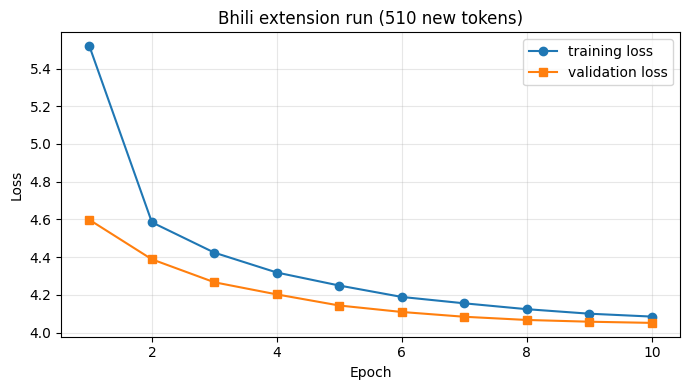

Total skipped gradient updates: 4


In [17]:
# Section 11.1: training history table and validation-loss plot
import matplotlib.pyplot as plt
hist_df = pd.DataFrame(S["history"])
if len(hist_df):
    display(hist_df.round(4))
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(hist_df["epoch"], hist_df["train_loss"], marker="o", label="training loss")
    ax.plot(hist_df["epoch"], hist_df["val_loss"], marker="s", label="validation loss")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Loss"); ax.set_title(f"Bhili extension run ({N_NEW} new tokens)")
    ax.grid(alpha=0.3); ax.legend(); fig.tight_layout()
    fig.savefig(RUN_DIR / "training_loss.png", dpi=150); plt.show()
else:
    print("No completed epochs recorded yet; run the training cell first.")
print("Total skipped gradient updates:", S.get("skipped", 0))

In [18]:
# Section 11.2: backup (download this zip; it allows resuming or evaluating in a later session)
shutil.make_archive(f"/kaggle/working/{RUN_NAME}_backup", "zip", RUN_DIR.parent, RUN_NAME)
print(f"Backup written: /kaggle/working/{RUN_NAME}_backup.zip (%.1f MB)" % (os.path.getsize(f"/kaggle/working/{RUN_NAME}_backup.zip") / 1e6))

Backup written: /kaggle/working/bhili_ext_f20_mean_s42_backup.zip (67.8 MB)


## Section 12. Evaluation under the baseline-matched pipeline

Use `IndicProcessor` prompts, batch size 8, **5 beams**, `max_new_tokens=256`, and no sampling to match the saved Bhili baseline inference settings. Generate predictions for the first 300 validation examples and all 990 test examples. Run the decoder integrity checks before reaching this section.

In [19]:
# Section 12.1: load best weights and define generation (baseline-matched settings)
best_path = RUN_DIR / "best_trainable.pt"
assert best_path.exists(), "No best_trainable.pt found: complete training first."
load_trainable(torch.load(best_path, map_location="cpu", weights_only=False))
lora_model.eval()
print("Loaded best trainable weights (validation loss %.4f)." % S["best_val"])

@torch.inference_mode()
def translate(sources, batch_size=8):
    prompts = [processor.preprocess_batch([s], src_lang=SRC_LANG, tgt_lang=TGT_LANG)[0] for s in sources]
    texts, id_lists = [], []
    for i in range(0, len(prompts), batch_size):
        enc = tok(prompts[i:i + batch_size], padding=True, truncation=True,
                  max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
        gen = lora_model.generate(**enc, max_new_tokens=256, num_beams=5, do_sample=False)
        for row in gen.cpu().tolist():
            id_lists.append(row)
            texts.append(decode_generated(row))
    texts = processor.postprocess_batch(texts, lang=TGT_LANG)
    return texts, id_lists

val_src = val_df[SRC_COL].astype(str).str.strip().tolist()[:300]
val_ref = val_df[TGT_COL].astype(str).str.strip().tolist()[:300]
test_src = test_df[SRC_COL].astype(str).str.strip().tolist()
test_ref = test_df[TGT_COL].astype(str).str.strip().tolist()

torch.cuda.empty_cache()
for source, reference, hypothesis in zip(val_src[:2], val_ref[:2], translate(val_src[:2])[0]):
    print("SRC:", source[:100]); print("REF:", reference[:100]); print("HYP:", hypothesis[:100]); print()

Loaded best trainable weights (validation loss 4.0514).
SRC: दूसरे शब्दों में, समानता प्रत्येक व्यक्ति के माध्यम से प्राप्त की जाती है जो अपनी क्षमता के अनुसार ख
REF: बिजा ब्रोह शब्‍दों मा समानता एक व्‍यक्ति ना वचमाना से की आपडी ताकत अनुसार खर्चा करे।
HYP: बीजा शब्दों मा समानता हरेक व्यक्ति ना माध्यम थी प्राप्त करी जाय से जी आपडी क्षमता ना अनुसार खर्च नो 

SRC: हमें इन मुद्दों पर साथ मिलकर काम करने के लिए शंघाई सहयोग संगठन भी एक महत्वपूर्ण ढांचा मुहैया कराएगा।
REF: हमु ने इना मुदा उपर हाते मलीने काम करवा हारू शंघाई सहयोग पार्टी पण एक खास ढ़ाचा आलवानों से ।
HYP: हमुने इना मुद्दा पर हाते मलीन काम करवा हारू शंघाई सहयोग संगठन पण एक महत्वपूर्ण ढांचा उपलब्ध करावहे।



In [20]:
# Section 12.2: generate validation (300 examples) and test (990 examples) predictions
preds, gen_ids = {}, {}
for split, sources, references in [("val300", val_src, val_ref), ("test", test_src, test_ref)]:
    t0 = time.time()
    hypotheses, ids = translate(sources)
    preds[split], gen_ids[split] = hypotheses, ids
    pd.DataFrame({"source": sources, "reference": references, "prediction": hypotheses}).to_csv(
        PRED_DIR / f"{RUN_NAME}_{split}.csv", index=False, encoding="utf-8-sig"
    )
    with open(PRED_DIR / f"{RUN_NAME}_{split}_generated_ids.json", "w", encoding="utf-8") as f:
        json.dump(ids, f)
    print(f"{split:7s} done in {(time.time() - t0) / 60:.1f} min")
print("Generated predictions for", len(preds["test"]), "held-out test examples.")

val300  done in 1.5 min
test    done in 4.1 min
Generated predictions for 990 held-out test examples.


## Section 13. Comparison with the Bhili baseline

The comparison loads the saved baseline predictions and checks that references and ordering match. It reports BLEU, chrF, TER, paired-bootstrap intervals over test examples (1,000 resamples), added-token usage, and subset analyses. Bootstrap intervals capture test-example resampling uncertainty, not variation across independent training runs. The target language tag is still an unverified proxy for Bhili.

In [21]:
# Section 13.1: metric helpers
import sacrebleu

def _has(pattern, text): return re.search(pattern, text) is not None

def summarize(system, split, hyp, ref):
    b = sacrebleu.corpus_bleu(hyp, [ref]); c = sacrebleu.corpus_chrf(hyp, [ref]); t = sacrebleu.corpus_ter(hyp, [ref])
    return {"system": system, "split": split, "n": len(ref), "BLEU": round(b.score, 2), "chrF": round(c.score, 2),
            "TER": round(t.score, 2),
            "word_len_ratio": round(sum(len(h.split()) for h in hyp) / sum(len(r.split()) for r in ref), 3),
            "empty": sum(h == "" for h in hyp)}

def paired_bootstrap(hyp_a, hyp_b, ref, B=1000, seed=0):
    rng = np.random.default_rng(seed); n = len(ref); d_bleu, d_chrf = [], []
    for _ in range(B):
        idx = rng.integers(0, n, n)
        r = [ref[i] for i in idx]; a = [hyp_a[i] for i in idx]; b = [hyp_b[i] for i in idx]
        d_bleu.append(sacrebleu.corpus_bleu(b, [r]).score - sacrebleu.corpus_bleu(a, [r]).score)
        d_chrf.append(sacrebleu.corpus_chrf(b, [r]).score - sacrebleu.corpus_chrf(a, [r]).score)
    return d_bleu, d_chrf

def show_bootstrap(label, hyp_a, hyp_b, ref, B=1000):
    d_bleu, d_chrf = paired_bootstrap(hyp_a, hyp_b, ref, B=B)
    out = {}
    for name, d in [("BLEU", d_bleu), ("chrF", d_chrf)]:
        lo, hi = np.percentile(d, [2.5, 97.5])
        out[name] = (float(np.mean(d)), float(lo), float(hi))
        print(f"{label} | {name}: mean {np.mean(d):+.2f}, 95% interval [{lo:+.2f}, {hi:+.2f}], B better in {100*np.mean(np.array(d) > 0):.1f}% of resamples")
    return out

def locate_file(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) + glob.glob(f"/kaggle/working/**/{name}", recursive=True)
    return hits[0] if hits else None
print("Helpers ready.")

Helpers ready.


In [22]:
# Section 13.2: load the saved Bhili baseline test predictions
# The baseline notebook saves evaluation/baseline_test_predictions.csv with columns
# Hindi, Reference_Bhili, Predicted_Bhili. It may be attached as a directory or ZIP.
def load_bhili_baseline_predictions(expected_references):
    direct_hits = []
    for root in [Path("/kaggle/working"), Path("/kaggle/input")]:
        if root.exists():
            direct_hits.extend(root.rglob("baseline_test_predictions.csv"))
    if direct_hits:
        frame = pd.read_csv(direct_hits[0], encoding="utf-8-sig")
        print("Loaded baseline predictions:", direct_hits[0])
    else:
        zip_hits = []
        for root in [Path("/kaggle/working"), Path("/kaggle/input")]:
            if root.exists():
                zip_hits.extend(root.rglob("bhili_baseline_artifacts.zip"))
        frame = None
        for zip_path in zip_hits:
            with zipfile.ZipFile(zip_path, "r") as zf:
                members = [n for n in zf.namelist() if n.endswith("baseline_test_predictions.csv")]
                if members:
                    with zf.open(members[0]) as handle:
                        frame = pd.read_csv(handle, encoding="utf-8-sig")
                    print("Loaded baseline predictions from:", zip_path, "member:", members[0])
                    break
        if frame is None:
            print("WARNING: baseline_test_predictions.csv was not found. Attach the baseline artifacts dataset/ZIP for comparative analysis.")
            return None

    needed = {"Reference_Bhili", "Predicted_Bhili"}
    assert needed.issubset(frame.columns), f"Unexpected baseline prediction columns: {frame.columns.tolist()}"
    baseline_references = frame["Reference_Bhili"].fillna("").astype(str).str.strip().tolist()
    baseline_hypotheses = frame["Predicted_Bhili"].fillna("").astype(str).str.strip().tolist()
    assert baseline_references == expected_references, "Baseline references/order differ from this notebook's held-out test split."
    assert len(baseline_hypotheses) == len(expected_references)
    return baseline_hypotheses

base_test = load_bhili_baseline_predictions(test_ref)
base_val = None  # existing baseline artifact contains test predictions, not validation predictions
print("Baseline test predictions available:", base_test is not None)

Baseline test predictions available: False


In [23]:
# Section 13.3: metrics, paired bootstrap, and added-token usage
this_name = f"Bhili extension ({N_NEW} tokens, {INIT} init, min_freq={MIN_FREQ})"
rows = []
if base_test is not None:
    rows.append(summarize("Bhili baseline LoRA", "test", base_test, test_ref))
rows.append(summarize(this_name, "test", preds["test"], test_ref))
score_table = pd.DataFrame(rows)
display(score_table)
score_table.to_csv(RUN_DIR / "scores.csv", index=False)

# How often did generation actually use new IDs?
test_has_added = np.array([any(int(t) >= BASE_TARGET_VOCAB_SIZE for t in ids) for ids in gen_ids["test"]])
used_ids = Counter(int(t) for ids in gen_ids["test"] for t in ids if int(t) >= BASE_TARGET_VOCAB_SIZE)
usage = {"test_sentences_using_an_added_token": int(test_has_added.sum()),
         "added_token_occurrences": int(sum(used_ids.values())),
         "distinct_added_tokens_used": len(used_ids), "added_tokens_available": N_NEW}
print("Added-token usage:", usage)

bleu_metric = sacrebleu.metrics.BLEU()
chrf_metric = sacrebleu.metrics.CHRF()
this_bleu = bleu_metric.corpus_score(preds["test"], [test_ref]).score
this_chrf = chrf_metric.corpus_score(preds["test"], [test_ref]).score
summary = {"run": RUN_NAME, "MIN_FREQ": MIN_FREQ, "INIT": INIT, "SEED": SEED, "N_NEW": N_NEW,
           "best_val_loss": S["best_val"], "completed_epochs": len(S["history"]),
           "test_BLEU": float(this_bleu), "test_chrF": float(this_chrf),
           "BLEU_signature": str(bleu_metric.get_signature()), "chrF_signature": str(chrf_metric.get_signature()),
           **usage, **stats}
if base_test is not None:
    base_bleu = sacrebleu.corpus_bleu(base_test, [test_ref]).score
    base_chrf = sacrebleu.corpus_chrf(base_test, [test_ref]).score
    print("\nPaired bootstrap on test examples (extension minus baseline):")
    bs = show_bootstrap("Bhili extension minus baseline", base_test, preds["test"], test_ref, B=1000)
    summary.update({"baseline_test_BLEU": float(base_bleu), "baseline_test_chrF": float(base_chrf),
                    "dBLEU_mean": bs["BLEU"][0], "dBLEU_lo": bs["BLEU"][1], "dBLEU_hi": bs["BLEU"][2],
                    "dchrF_mean": bs["chrF"][0], "dchrF_lo": bs["chrF"][1], "dchrF_hi": bs["chrF"][2]})
json.dump(summary, open(RUN_DIR / "run_summary.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
print("\nSacreBLEU signature:", bleu_metric.get_signature())
print("chrF signature:", chrf_metric.get_signature())

,system,split,n,BLEU,chrF,TER,word_len_ratio,empty
0,"Bhili extension (510 tokens, mean init, min_fr...",test,990,13.09,44.37,69.96,0.986,0


Added-token usage: {'test_sentences_using_an_added_token': 739, 'added_token_occurrences': 1663, 'distinct_added_tokens_used': 210, 'added_tokens_available': 510}

SacreBLEU signature: nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0
chrF signature: nrefs:1|case:mixed|eff:yes|nc:6|nw:0|space:no|version:2.6.0


In [24]:
# Section 13.4: where does any difference come from?
if base_test is None:
    print("Skipped: attach the saved Bhili baseline predictions to compare systems.")
else:
    ref_has_added = np.array([added_pattern.search(ref) is not None for ref in test_ref])
    def subset_delta(indices):
        refs = [test_ref[i] for i in indices]
        base = [base_test[i] for i in indices]
        ext = [preds["test"][i] for i in indices]
        if not refs:
            return float("nan"), float("nan")
        return (sacrebleu.corpus_bleu(ext, [refs]).score - sacrebleu.corpus_bleu(base, [refs]).score,
                sacrebleu.corpus_chrf(ext, [refs]).score - sacrebleu.corpus_chrf(base, [refs]).score)
    rows = []
    for label, mask in [("all test examples", np.ones(len(test_ref), dtype=bool)),
                        ("extension output used", test_has_added),
                        ("extension output not used", ~test_has_added),
                        ("reference contains candidate", ref_has_added),
                        ("reference contains no candidate", ~ref_has_added)]:
        idx = np.where(mask)[0].tolist()
        db, dc = subset_delta(idx)
        rows.append({"subset": label, "n": len(idx), "delta_BLEU": round(float(db), 3), "delta_chrF": round(float(dc), 3)})
    subset_df = pd.DataFrame(rows)
    display(subset_df)
    subset_df.to_csv(RUN_DIR / "subset_analysis.csv", index=False)
    print("Subset differences are diagnostic; small subsets can have noisy metrics.")

Skipped: attach the saved Bhili baseline predictions to compare systems.


In [25]:
# Section 13.5: examples (first 5 test sentences)
for i in range(5):
    print(f"[{i}] SRC : {test_src[i][:110]}")
    print(f"    REF : {test_ref[i][:110]}")
    if base_test is not None:
        print(f"    BASE: {base_test[i][:110]}")
    print(f"    RUN : {preds['test'][i][:110]}\n")

[0] SRC : ज़ोया तब रुद्र को छुड़ाती है और वे वाली का पीछा करते हैं।
    REF : जोया तेर रूद्र ने छोड़े से अने त्यों वाली ना पीछा करे से !
    RUN : जोया फेर रुद्र ने छोडे से अने ते वाली नो पीछो करे से।

[1] SRC : इसके अलावा उन्होंने न केवल अपनी विद्वद्-जिज्ञासा के समाधान के लिए, बल्कि प्राचीन संस्कृत नाटकों के प्रदर्शन मे
    REF : इना ने अलावा तीहू यी न खाली तमारा ज्ञान ने जाणवा हारू केम के जूना रीतिण्रिवाज नी नाटकों मा वताड़वा मा आपणी भणतर
    RUN : इना अलावा तिहुने खाली आपडी विद्वता-जिज्ञासा ना समाधान हारू नहीं पण प्राचीन संस्कृत नाटकों ना प्रदर्शन मा आपडा 

[2] SRC : वेट लॉस के लिए आपको हेल्दी डायट लेना होगा और एक्टिव लाइफस्टाइल अपनानी होगी।
    REF : शरीर न भार कम करवा हारू तिहु ने असल भोजन लेवा जोवे अने रोज असल कामकाज वाला दन अपणावा होवे ।
    RUN : वेट लॉस हारू तमुने स्वस्थ आहार लेवो पडे अने सक्रिय जीवन शैली अपनावी पडे।

[3] SRC : उनका दावा था कि आगामी विधानसभा चुनाव में कांग्रेस को बहुमत मिलेगा।
    REF : तिहूनों दावों हटों की अगली विधानसवा सुनाव मां कांग्रेश बहुमत लाव ही
    RUN :

## Section 14. Save everything

The recovery backup contains optimizer/scheduler/scaler state and is useful for resuming training. The smaller results bundle contains the best trainable state, candidate mapping, test predictions, metrics, and history; it does not duplicate latest/final recovery checkpoints. Download both if you need resumability **and** a shareable result package.

In [26]:
# Section 14.1: create a compact result bundle plus portable trainable state
from IPython.display import FileLink, display

# Save all mapping and metadata needed to rebuild this custom vocabulary in the same notebook code.
portable_dir = RUN_DIR / "portable_model_bundle"
portable_dir.mkdir(parents=True, exist_ok=True)
assert (RUN_DIR / "best_trainable.pt").exists(), "Best trainable checkpoint is missing."
shutil.copy2(RUN_DIR / "best_trainable.pt", portable_dir / "best_trainable.pt")
shutil.copy2(RUN_DIR / "extended_vocabulary.json", portable_dir / "extended_vocabulary.json")
shutil.copy2(RUN_DIR / "experiment_config.json", portable_dir / "experiment_config.json")
metadata = {
    "base_model": MODEL_ID, "source_language": SRC_LANG, "target_language_tag_proxy": TGT_LANG,
    "language_tag_verified_for_Bhili": False, "min_frequency": MIN_FREQ, "initialization": INIT,
    "seed": SEED, "base_target_vocab_size": BASE_TARGET_VOCAB_SIZE,
    "extended_target_vocab_size": EXTENDED_VOCAB_SIZE, "new_tokens": N_NEW,
    "best_validation_loss": float(S["best_val"]), "completed_epochs": len(S["history"]),
    "note": "Custom trainable state and vocabulary map require this notebook's wrapper/decoder code; base model weights are not included."
}
with open(portable_dir / "model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

# Explicit allowlist: avoid accidentally packaging optimizer recovery checkpoints multiple times.
include_paths = [
    RUN_DIR / "experiment_config.json", RUN_DIR / "extended_vocabulary.json",
    RUN_DIR / "selected_vocabulary.csv", RUN_DIR / "tokenization_stats.json",
    RUN_DIR / "training_history.json", RUN_DIR / "training_loss.png",
    RUN_DIR / "scores.csv", RUN_DIR / "run_summary.json", RUN_DIR / "subset_analysis.csv",
    RUN_DIR / "predictions" / f"{RUN_NAME}_val300.csv", RUN_DIR / "predictions" / f"{RUN_NAME}_test.csv",
    RUN_DIR / "portable_model_bundle" / "best_trainable.pt",
    RUN_DIR / "portable_model_bundle" / "extended_vocabulary.json",
    RUN_DIR / "portable_model_bundle" / "experiment_config.json",
    RUN_DIR / "portable_model_bundle" / "model_metadata.json",
]
include_paths = [p for p in include_paths if p.exists()]
ZIP_PATH = Path("/kaggle/working") / f"{RUN_NAME}_results.zip"
if ZIP_PATH.exists(): ZIP_PATH.unlink()
with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=6) as zf:
    for path in include_paths:
        zf.write(path, path.relative_to(RUN_DIR))
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    bad = zf.testzip()
    assert bad is None, f"ZIP integrity failed at {bad}"
    print("Files packaged:", len(zf.namelist()))
print("Results bundle:", ZIP_PATH)
print("ZIP size: %.2f MB" % (ZIP_PATH.stat().st_size / (1024**2)))
print("ZIP verified: True")
display(FileLink(str(ZIP_PATH), result_html_prefix="Download compact results bundle: "))

Files packaged: 14
Results bundle: /kaggle/working/bhili_ext_f20_mean_s42_results.zip
ZIP size: 16.55 MB
ZIP verified: True


/kaggle/working/bhili_ext_f20_mean_s42_results.zip